# Instructions

1. Tracer un spectrogramme
    - Charger le fichier audio sweep_ref.wav
    - Tracer son spectrogramme à l'aide de la fonction `spectrogram` du module `scipy.signal`

2. Créer un spectrogramme à la main
    - Charger le fichier audio sweep_ref.wav
    - Définir une taille de bloc (e.g. 0.1 sec), créer une boucle `for` permettant d'itérer sur des blocs/segments temporels de ce fichier audio
    - Calculer la FFT $X$ de chaque bloc et sauvegarder le vecteur $Y = 20*np.log(np.abs(X))$ dans une ligne d'une matrice $S$, initialisée avant la boucle
    - Utiliser la fonction `pcolormesh` du module `matplotlib.pyplot` pour afficher $S$, créer pour ce faire un vecteur temps et fréquence correspondant aux colonnes et lignes de la matrice $S$.

# Correction

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import math
from IPython.display import Audio
import scipy

## 1. Tracer un spectrogramme

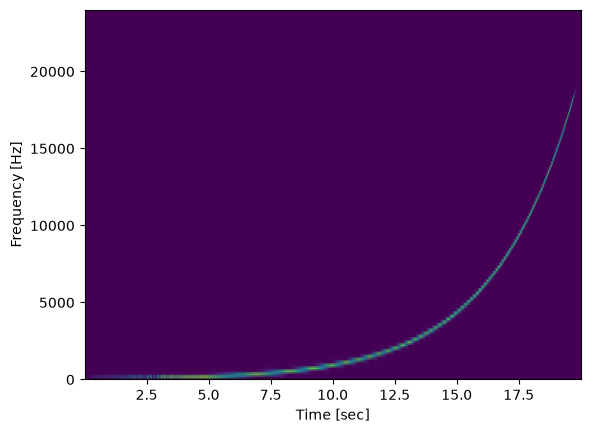

In [3]:
# load audio file
fs, x = scipy.io.wavfile.read('../assets/sweep_ref.wav')
x = x / np.max(np.abs(x))

# spectrogram
f, t, Sxx = scipy.signal.spectrogram(x, fs)

plt.pcolormesh(t, f, Sxx, shading='gouraud')
plt.ylabel('Frequency [Hz]')
plt.xlabel('Time [sec]')
# plt.ylim([20, 10000])
plt.show()

## 2. Créer un spectrogramme à la main

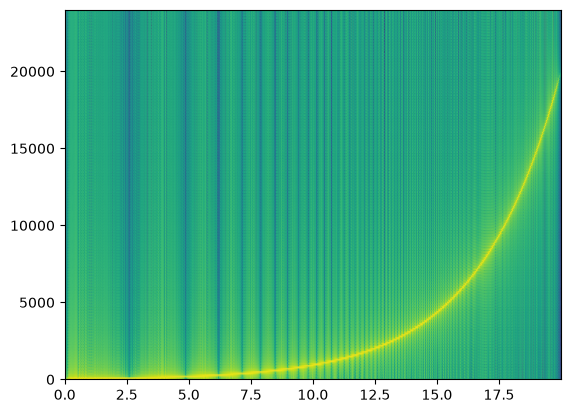

In [4]:
# load audio file
fs, x = scipy.io.wavfile.read('../assets/sweep_ref.wav')
x = x / np.max(np.abs(x))

# init locals
block_duration_in_sec = 0.01
n_sample_per_block = math.ceil(block_duration_in_sec * fs)
n_blocks = math.floor( len(x) / n_sample_per_block )
S = np.zeros([n_blocks, round(n_sample_per_block/2)+1])

# loop over blocks
for i_block in range(n_blocks):

    # extract audio
    selvect = np.arange(n_sample_per_block) + i_block * n_sample_per_block
    
    # fft
    X = np.fft.rfft(x[selvect], n_sample_per_block)
    X = 20*np.log(np.abs(X))

    # save to locals
    S[i_block, :] = X

# plot
t = n_sample_per_block * np.arange(n_blocks) / fs
f = np.fft.rfftfreq(n_sample_per_block, 1/fs)
plt.pcolormesh(t, f, np.transpose(S), shading="gouraud")
# plt.yscale('log')
plt.show()